In [2]:
# ==========================================
# 0. MONTAR GOOGLE DRIVE E INSTALAR DEPENDENCIAS
# ==========================================
from google.colab import drive
import os
import json
import orjson
import pandas as pd
from collections import defaultdict

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ==========================================
# 1. CONFIGURACIÓN DE RUTAS SEGÚN TUS CARPETAS
# ==========================================
BASE_DRIVE = '/content/drive/MyDrive/TFG/data'

DIR_PEMR = os.path.join(BASE_DRIVE, 'PatientEncounterMedRequest')
DIR_VARIOS = os.path.join(BASE_DRIVE, 'Varios')
DIR_REST = os.path.join(BASE_DRIVE, 'Rest')

# Carpeta local temporal en Colab para guardar el resultado de salida sin llenar tu PC
OUTPUT_DIR = '/content/output_tfg'
os.makedirs(OUTPUT_DIR, exist_ok=True)
OUTPUT_FILE = os.path.join(OUTPUT_DIR, 'medication_request_dataset_full.jsonl')

# Rutas de los archivos distribuidos en tus 3 carpetas
PATIENT_FILE = os.path.join(DIR_PEMR, 'MimicPatient.ndjson')
MED_REQUEST_FILE = os.path.join(DIR_PEMR, 'MimicMedicationRequest.ndjson')
ENCOUNTER_FILES = [
    os.path.join(DIR_PEMR, 'MimicEncounter.ndjson'),
    os.path.join(DIR_REST, 'MimicEncounterED.ndjson')
]
CONDITION_FILES = [
    os.path.join(DIR_VARIOS, 'MimicCondition.ndjson'),
    os.path.join(DIR_REST, 'MimicConditionED.ndjson')
]
MED_FILE = os.path.join(DIR_VARIOS, 'MimicMedication.ndjson')
ADMIN_FILE = os.path.join(DIR_REST, 'MimicMedicationAdministration.ndjson')
PROCEDURE_FILES = [
    os.path.join(DIR_VARIOS, 'MimicProcedure.ndjson')
]

# El CSV de prescripciones (asegúrate de subirlo también a la carpeta TFG de tu Drive si no lo tienes local)
CSV_MEDICOS = os.path.join(BASE_DRIVE, 'prescriptions.csv.gz')

In [3]:
# ==========================================
# 2. HERRAMIENTAS BASE
# ==========================================
# Lee los archivos línea a línea de forma eficiente
# y los convierte de texto plano a diccionarios de Python,
# incluyendo un control de errores por si alguna línea viene corrupta.
def iter_ndjson(path, stats):
    if not os.path.exists(path):
        print(f"⚠️ Aviso: No se encontró {path}")
        return
    with open(path, 'rt', encoding='utf-8', errors='ignore') as f:
        for line in f:
            if not line.strip(): continue
            try:
                yield orjson.loads(line)
            except orjson.JSONDecodeError:
                stats['json_errors'] += 1

# Es una función de seguridad fundamental para trabajar con estándares FHIR.
# Los datos anidados en salud suelen tener estructuras complejas (diccionarios dentro de diccionarios)
# Si un campo no existe, dig evita que el script falle por un error de clave (KeyError)
# y devuelve un valor por defecto de manera limpia.
def dig(d, *path, default=None):
    for k in path:
        try:
            d = d[k]
        except (KeyError, IndexError, TypeError):
            return default
    return d

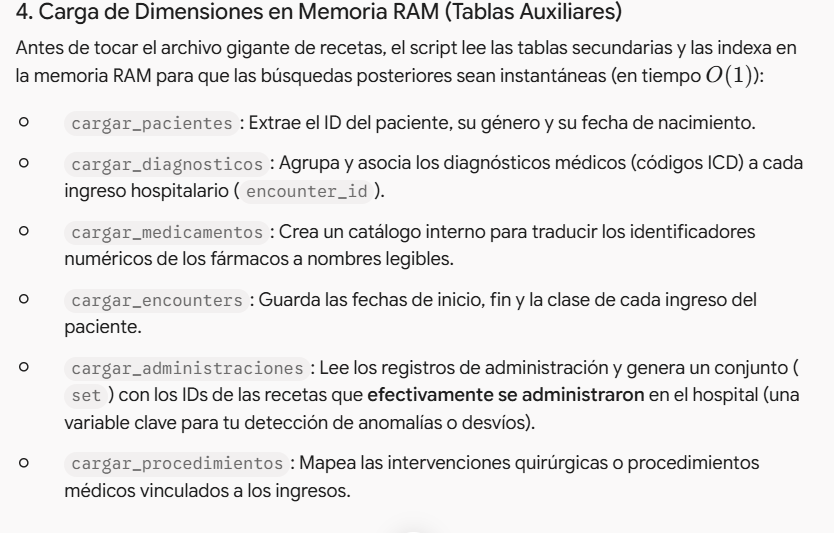

In [4]:
# ==========================================
# 3. FUNCIONES DE CARGA EN RAM (DIMENSIONES)
# ==========================================
def cargar_pacientes(filepath, stats):
    print(f"⏳ Cargando pacientes...")
    diccionario = {}
    for paciente in iter_ndjson(filepath, stats):
        diccionario[paciente.get('id')] = {
            'patient_gender': paciente.get('gender', 'unknown'),
            'patient_birthdate': paciente.get('birthDate', 'unknown')
        }
    return diccionario

def cargar_diagnosticos(filepaths, stats):
    print(f"⏳ Cargando diagnósticos...")
    por_enc = defaultdict(dict)
    for filepath in filepaths:
        for cond in iter_ndjson(filepath, stats):
            enc_ref = dig(cond, 'encounter', 'reference', default='')
            enc_id = enc_ref.rsplit('/', 1)[-1] if '/' in enc_ref else ''
            cod = dig(cond, 'code', 'coding', 0, 'code', default='UNKNOWN')
            txt = dig(cond, 'code', 'coding', 0, 'display', default='No description')
            if enc_id:
                por_enc[enc_id][cod] = txt
    return por_enc

def cargar_medicamentos(filepath, stats):
    print(f"⏳ Cargando catálogo de medicamentos...")
    diccionario = {}
    for med in iter_ndjson(filepath, stats):
        med_id = med.get('id')
        med_name = "unknown"
        for ident in med.get('identifier', []):
            if 'mimic-medication-name' in ident.get('system', ''):
                med_name = ident.get('value', 'unknown')
                break
        if med_name == "unknown":
            med_name = dig(med, 'code', 'text', default="unknown")
        diccionario[med_id] = med_name
    return diccionario

def cargar_encounters(filepaths, stats):
    print(f"⏳ Cargando ingresos hospitalarios...")
    diccionario = {}
    for filepath in filepaths:
        for enc in iter_ndjson(filepath, stats):
            diccionario[enc.get('id')] = {
                'encounter_class': dig(enc, 'class', 'code', default='unknown'),
                'encounter_start': dig(enc, 'period', 'start', default=''),
                'encounter_end': dig(enc, 'period', 'end', default=''),
                'encounter_service_type': dig(enc, 'serviceType', 'coding', 0, 'code', default='unknown')
            }
    return diccionario

def cargar_administraciones(filepath, stats):
    print(f"⏳ Cargando registros de administración...")
    administraciones = set()
    for admin in iter_ndjson(filepath, stats):
        req_ref = dig(admin, 'request', 'reference', default='')
        req_id = req_ref.rsplit('/', 1)[-1] if '/' in req_ref else ''
        if req_id:
            administraciones.add(req_id)
    return administraciones

def cargar_procedimientos(filepaths, stats):
    print(f"⏳ Cargando procedimientos...")
    por_enc = defaultdict(dict)
    for filepath in filepaths:
        for proc in iter_ndjson(filepath, stats):
            enc_ref = dig(proc, 'encounter', 'reference', default='')
            if not enc_ref:
                enc_ref = proc.get('encounter', '')
                if isinstance(enc_ref, dict):
                    enc_ref = enc_ref.get('reference', '')
            enc_id = enc_ref.rsplit('/', 1)[-1] if '/' in enc_ref else str(enc_ref)
            cod = dig(proc, 'code', 'coding', 0, 'code', default='UNKNOWN')
            txt = dig(proc, 'code', 'coding', 0, 'display', default='No description')
            if enc_id and enc_id != '':
                por_enc[enc_id][cod] = txt
    return por_enc

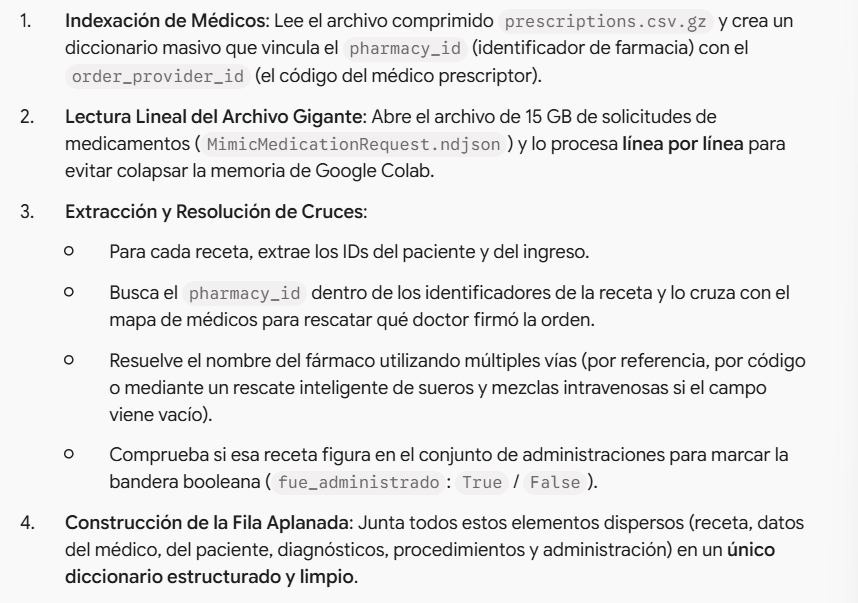

In [5]:
# ==========================================
# 4. PROCESAMIENTO MAESTRO (ETL)
# ==========================================
def procesar_etl_completo():
    print("⏳ Cargando el mapa de médicos...")
    if not os.path.exists(CSV_MEDICOS):
        print(f"❌ No se encuentra el archivo CSV en {CSV_MEDICOS}. Súbelo a la carpeta TFG de Drive.")
        return

    df = pd.read_csv(CSV_MEDICOS, usecols=['pharmacy_id', 'order_provider_id'], dtype=str)
    mapa_medicos = pd.Series(df.order_provider_id.values, index=df.pharmacy_id.astype(str)).to_dict()
    print(f"✅ Mapa de médicos cargado: {len(mapa_medicos)} registros indexados.")

    if not os.path.exists(MED_REQUEST_FILE):
        print(f"❌ No se encuentra el archivo principal en: {MED_REQUEST_FILE}")
        return

    stats = defaultdict(int)

    pacientes = cargar_pacientes(PATIENT_FILE, stats)
    diagnosticos = cargar_diagnosticos(CONDITION_FILES, stats)
    procedimientos = cargar_procedimientos(PROCEDURE_FILES, stats)
    medicamentos = cargar_medicamentos(MED_FILE, stats)
    encounters = cargar_encounters(ENCOUNTER_FILES, stats)
    administraciones = cargar_administraciones(ADMIN_FILE, stats)

    print(f"🚀 Iniciando ETL completo en Google Colab...")

    contador_exito = 0
    contador_total = 0

    with open(MED_REQUEST_FILE, 'rt', encoding='utf-8', errors='ignore') as f_in, \
         open(OUTPUT_FILE, 'wb') as f_out:

        for linea in f_in:
            linea_limpia = linea.strip()
            if not linea_limpia:
                continue
            try:
                receta = json.loads(linea_limpia)
            except (json.JSONDecodeError, MemoryError):
                stats['json_errors'] += 1
                continue

            contador_total += 1
            stats['total_recetas_procesadas'] += 1

            # 1. Obtención de IDs principales
            req_id = receta.get('id')
            patient_id = dig(receta, 'subject', 'reference', default='').rsplit('/', 1)[-1]
            encounter_id = dig(receta, 'encounter', 'reference', default='').rsplit('/', 1)[-1]

            # 2. Cruce para obtener el médico prescriptor
            pharmacy_id = None
            for ident in receta.get('identifier', []):
                val = str(ident.get('value', ''))
                if val:
                    pharmacy_id = val
                    break

            requester_id = mapa_medicos.get(pharmacy_id, None)

            # 🛑 FILTRO CLAVE: Si la receta no tiene médico asociado, la descartamos
            if not requester_id:
                stats['recetas_sin_medico_descartadas'] += 1 #simplemente un contador
                continue #ignora todo y pasa  a la siguiente linea del archivo

            contador_exito += 1

            # 3. Resolución de nombres de medicamentos
            medication_id = dig(receta, 'medicationReference', 'reference', default='').rsplit('/', 1)[-1]
            medication_name = medicamentos.get(medication_id, 'unknown') if medication_id else 'unknown'

            if medication_name == 'unknown':
                concept_text = dig(receta, 'medicationCodeableConcept', 'text')
                if concept_text:
                    medication_name = concept_text
                else:
                    concept_display = dig(receta, 'medicationCodeableConcept', 'coding', 0, 'display')
                    concept_code = dig(receta, 'medicationCodeableConcept', 'coding', 0, 'code')
                    if concept_display: medication_name = concept_display
                    elif concept_code: medication_name = concept_code

            if medication_name == 'unknown':
                texto_dosis = dig(receta, 'dosageInstruction', 0, 'text', default='')
                route = dig(receta, 'dosageInstruction', 0, 'route', 'coding', 0, 'code', default='')
                if texto_dosis and (route == 'IV' or any(term in texto_dosis.lower() for term in ['bag', 'bottle', 'premix', 'soln', 'iv', 'infusion'])):
                    medication_name = f"IV Fluid / Mix: {texto_dosis}"
                else:
                    medication_name = f"Unknown Oral/Other: {texto_dosis}" if texto_dosis else "unknown"

            if patient_id not in pacientes: stats['miss_patient'] += 1
            if encounter_id not in encounters: stats['miss_encounter'] += 1
            if medication_name == 'unknown': stats['miss_medication'] += 1

            datos_paciente = pacientes.get(patient_id, {'patient_gender': 'unknown', 'patient_birthdate': 'unknown'})

            # Recuperamos los datos del encuentro (incluyendo el service_type que añadimos)
            datos_encounter = encounters.get(encounter_id, {
                'encounter_class': 'unknown',
                'encounter_start': '',
                'encounter_end': '',
                'encounter_service_type': 'unknown'
            })

            dict_diags = diagnosticos.get(encounter_id, {})
            diags_texto = " | ".join([f"{cod}: {txt}" for cod, txt in dict_diags.items()]) if dict_diags else "No diagnosis recorded"

            dict_procs = procedimientos.get(encounter_id, {})
            procs_texto = " | ".join([f"{cod}: {txt}" for cod, txt in dict_procs.items()]) if dict_procs else "No procedure recorded"

            fue_administrado = req_id in administraciones

            dosage_text = dig(receta, 'dosageInstruction', 0, 'text', default='')
            route_code = dig(receta, 'dosageInstruction', 0, 'route', 'coding', 0, 'code', default='')
            timing_code = dig(receta, 'dosageInstruction', 0, 'timing', 'code', 'coding', 0, 'code', default='')
            dose_value = dig(receta, 'dosageInstruction', 0, 'doseAndRate', 0, 'doseQuantity', 'value')
            dose_unit = dig(receta, 'dosageInstruction', 0, 'doseAndRate', 0, 'doseQuantity', 'unit', default='')

            fila_aplanada = {
                'IdMedicationRequest': req_id,
                'authoredOn': receta.get('authoredOn'),
                'pharmacy_id': pharmacy_id,
                'order_provider_id': requester_id,
                'fue_administrado': fue_administrado,

                'encounter_id': encounter_id,
                'encounter_class': datos_encounter['encounter_class'],
                'encounter_start': datos_encounter['encounter_start'],
                'encounter_end': datos_encounter['encounter_end'],
                'encounter_service_type': datos_encounter['encounter_service_type'],
                'encounter_diagnoses': diags_texto,
                'encounter_procedures': procs_texto,

                'patient_id': patient_id,
                'patient_gender': datos_paciente['patient_gender'],
                'patient_birthdate': datos_paciente['patient_birthdate'],

                'medication_id': medication_id,
                'medication_name': medication_name,
                'route_code': route_code,
                'timing_code': timing_code,
                'dose_value': dose_value,
                'dose_unit': dose_unit,
                'dosage_text': dosage_text
            }

            f_out.write(orjson.dumps(fila_aplanada) + b'\n')

            if contador_total % 500000 == 0:
                print(f"   Procesadas {contador_total} recetas...")

    print(f"\n🎉 ¡ETL completado con éxito en Google Colab!")
    print(f"  - Total de recetas procesadas: {contador_total}")
    print(f"  - Con médico vinculado correctamente: {contador_exito}")
    print(f"  - Archivo final guardado temporalmente en: {OUTPUT_FILE}")

    # Opcional: Copiar el resultado final directamente de vuelta a tu Google Drive para tenerlo seguro
    import shutil
    drive_output_path = os.path.join(BASE_DRIVE, 'medication_request_dataset_full.jsonl')
    shutil.copy(OUTPUT_FILE, drive_output_path)
    print(f"📁 Archivo final copiado automáticamente a tu Google Drive en: {drive_output_path}")

if __name__ == "__main__":
    procesar_etl_completo()

⏳ Cargando el mapa de médicos...
✅ Mapa de médicos cargado: 17779025 registros indexados.
⏳ Cargando pacientes...
⏳ Cargando diagnósticos...
⏳ Cargando procedimientos...
⏳ Cargando catálogo de medicamentos...
⏳ Cargando ingresos hospitalarios...
⏳ Cargando registros de administración...
🚀 Iniciando ETL completo en Google Colab...
   Procesadas 500000 recetas...
   Procesadas 1500000 recetas...
   Procesadas 2000000 recetas...
   Procesadas 3500000 recetas...
   Procesadas 4000000 recetas...
   Procesadas 5500000 recetas...
   Procesadas 12000000 recetas...

🎉 ¡ETL completado con éxito en Google Colab!
  - Total de recetas procesadas: 15416901
  - Con médico vinculado correctamente: 2405336
  - Archivo final guardado temporalmente en: /content/output_tfg/medication_request_dataset_full2.jsonl
📁 Archivo final copiado automáticamente a tu Google Drive en: /content/drive/MyDrive/TFG/data/medication_request_dataset_full.jsonl


# INSPECCIÓN DE RESULTADOS

In [5]:
import json
import os
import random

# Ruta de tu archivo resultante en Google Drive
archivo_resultado = '/content/drive/MyDrive/TFG/data/medication_request_dataset_full.jsonl'

if not os.path.exists(archivo_resultado):
    print(f"❌ No se encuentra el archivo en: {archivo_resultado}")
else:
    print(f"🔍 Inspeccionando 20 registros aleatorios de las primeras 1,000 líneas:\n")
    print("-" * 60)

    lineas_cargadas = []
    with open(archivo_resultado, 'rt', encoding='utf-8') as f:
        for i in range(1000):
            linea = f.readline()
            if not linea:
                break
            lineas_cargadas.append((i + 1, linea.strip()))

    # Seleccionamos 20 al azar (o menos de 20 si el archivo tuviera menos de 10 líneas)
    muestra_aleatoria = random.sample(lineas_cargadas, min(20, len(lineas_cargadas)))

    # Ordenamos por su número de línea original para que se muestren en orden de aparición
    muestra_aleatoria.sort(key=lambda x: x[0])

    for idx, (num_linea, contenido_linea) in enumerate(muestra_aleatoria):
        try:
            datos = json.loads(contenido_linea)
            print(f"Muestra {idx + 1} (Línea original #{num_linea}):")
            print(json.dumps(datos, indent=4, ensure_ascii=False))
        except json.JSONDecodeError:
            print(f"Muestra {idx + 1} (Línea #{num_linea} - Error de JSON): {contenido_linea}")
        print("-" * 60)

🔍 Inspeccionando 20 registros aleatorios de las primeras 1,000 líneas:

------------------------------------------------------------
Muestra 1 (Línea original #29):
{
    "IdMedicationRequest": "717d6b54-bdb2-5fe1-8bf4-3ad3a9155dea",
    "authoredOn": "2153-04-12T11:22:57-04:00",
    "pharmacy_id": "10489487",
    "order_provider_id": "P59OUH",
    "fue_administrado": false,
    "encounter_id": "05edfb99-2b95-5379-9a6f-cd34df711872",
    "encounter_class": "OBSENC",
    "encounter_start": "2153-04-12T09:27:00-04:00",
    "encounter_end": "2153-04-12T17:30:00-04:00",
    "encounter_service_type": "NMED",
    "encounter_diagnoses": "I639: Cerebral infarction, unspecified | R4701: Aphasia | G8194: Hemiplegia, unspecified affecting left nondominant side | R29810: Facial weakness | I4891: Unspecified atrial fibrillation | Z66: Do not resuscitate | K219: Gastro-esophageal reflux disease without esophagitis | Z7902: Long term (current) use of antithrombotics/antiplatelets | I10: Essential (pr